# Comparing two artifact-detection features: slope vs. half-amplitude width

**Goal.** Some detected peaks in `peaks_combined2_sorted.npy` look like
artifacts on the waveform (too narrow to be biological). This notebook tests
**two** candidate features against your own hand labels, before either goes
anywhere near the detection pipeline:

- **Method 1 — slope**: $\text{trace}[\text{peak}] - \text{trace}[\text{peak}-1]$
- **Method 2 — half-amplitude width**: the number of samples between the two
  points, either side of the peak, where the waveform crosses half the peak
  amplitude (a FWHM/half-width-style spike-duration measure).

Workflow:

1. Load the detected peaks and the recording they were detected on.
2. Compute both features for every peak (chunked so it scales to millions of
   peaks).
3. Hand-label a sample of peaks (0 = real spike, 1 = artifact) with an
   interactive waveform viewer. Labels persist across sessions in a CSV —
   `N_LABEL` is your **total** target label count, not "how many more".
4. For each method: plot the slope/half-width distribution split by label,
   run an ROC/threshold search, and report a suggested cutoff.
5. Compare the two methods directly: find peaks the two suggested thresholds
   would classify *differently*, and look at their waveforms (±3 channels,
   ±5 ms) to see which method is right.

**Prerequisites** (same environment `peak_localisation.py` runs in):
`numpy`, `pandas`, `matplotlib`, `ipywidgets`, `tqdm`, and the `spikeinterface`
+ `peak_detect_localise` packages. `scikit-learn` is optional (manual
ROC/AUC fallback included).


In [6]:
import re
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import ipywidgets as widgets
from IPython.display import display, clear_output

# Same loader peak_localisation.py uses, so recording loading behaves
# identically (handles preprocessed folders / temp_wh.dat / SpikeGLX).
from mua_pipeline import load_data as load_data_mua

try:
    from sklearn.metrics import roc_curve, roc_auc_score
    _HAVE_SKLEARN = True
except ImportError:
    _HAVE_SKLEARN = False

    def roc_curve(y, score):
        y = np.asarray(y); score = np.asarray(score)
        thresholds = np.unique(score)[::-1]
        thresholds = np.concatenate([[thresholds[0] + 1], thresholds])
        P, N = (y == 1).sum(), (y == 0).sum()
        tpr, fpr = [], []
        for t in thresholds:
            pred = score >= t
            tp = ((pred == 1) & (y == 1)).sum()
            fp = ((pred == 1) & (y == 0)).sum()
            tpr.append(tp / P if P else 0.0)
            fpr.append(fp / N if N else 0.0)
        return np.array(fpr), np.array(tpr), thresholds

    def roc_auc_score(y, score):
        fpr, tpr, _ = roc_curve(y, score)
        order = np.argsort(fpr)
        return np.trapz(tpr[order], fpr[order])

    print("scikit-learn not found -- using a manual ROC/AUC fallback. "
          "`pip install scikit-learn` for the real implementation.")


## 1. Config

In [7]:
# --- Peaks produced by peak_localisation.py ---
PEAKS_PATH = Path(r"/nexus/posix0/MBR-neuralsystems/ephys/GLC7248/GLC7248_a_g1/preprocessed/thresholding_peaks_3.5_ts5600_teend/_sliced_recording/thresholding_peaks_3.5_ts5600_teend/peaks_combined2_sorted.npy")
RECORDING_PATH = Path(r"/nexus/posix0/MBR-neuralsystems/ephys/GLC7248/GLC7248_a_g1/preprocessed")
SAMPLE_INDEX_OFFSET = 0  # sample_index needs no shift against RECORDING_PATH above
LABELS_PATH = PEAKS_PATH.parent / "hand_labels_slope_test.csv"

# --- Labeling session ---
N_LABEL = 200          # how many peaks to queue up for hand-labeling
SEED = 0                # fixed seed -> labeling queue is reproducible/resumable
SHOW_SLOPE_DURING_LABELING = False  # keep False for an unbiased blind label;
                                     # flip to True to sanity-check the metric later

# --- Waveform snippet shown while labeling ---
WINDOW_MS = 30.0          # total width of the time window shown, centered on the peak
N_CONTEXT_CHANNELS = 10   # channels shown above/below the peak channel for context

# --- Slope computation ---
CHUNK_DURATION_S = 5.0   # trace-loading chunk size for the vectorized slope pass

print("PEAKS_PATH      =", PEAKS_PATH)
print("RECORDING_PATH  =", RECORDING_PATH)
print("SAMPLE_INDEX_OFFSET =", SAMPLE_INDEX_OFFSET)
print("LABELS_PATH     =", LABELS_PATH)


PEAKS_PATH      = /nexus/posix0/MBR-neuralsystems/ephys/GLC7248/GLC7248_a_g1/preprocessed/thresholding_peaks_3.5_ts5600_teend/_sliced_recording/thresholding_peaks_3.5_ts5600_teend/peaks_combined2_sorted.npy
RECORDING_PATH  = /nexus/posix0/MBR-neuralsystems/ephys/GLC7248/GLC7248_a_g1/preprocessed
SAMPLE_INDEX_OFFSET = 0
LABELS_PATH     = /nexus/posix0/MBR-neuralsystems/ephys/GLC7248/GLC7248_a_g1/preprocessed/thresholding_peaks_3.5_ts5600_teend/_sliced_recording/thresholding_peaks_3.5_ts5600_teend/hand_labels_slope_test.csv


## 2. Load peaks

In [8]:
peaks = np.load(PEAKS_PATH)
print(f"Loaded {len(peaks):,} peaks")
print("Fields:", peaks.dtype.names)
print(peaks[:5])
print()
print("sample_index range:", peaks['sample_index'].min(), "-", peaks['sample_index'].max())
print("channel_index range:", peaks['channel_index'].min(), "-", peaks['channel_index'].max())


Loaded 5,855,870 peaks
Fields: ('sample_index', 'channel_index', 'amplitude', 'segment_index', 'z', 'matched_filter_score')
[(168000064,  37, -6.0039062, 0, 0, nan)
 (168000074,  70, -3.8320312, 0, 0, nan)
 (168000141, 163, -3.1738281, 0, 0, nan)
 (168000203, 165, -3.6152344, 0, 0, nan)
 (168000217, 193, -5.1953125, 0, 0, nan)]

sample_index range: 168000064 - 292622348
channel_index range: 0 - 315


## 3. Load the recording

`sample_index` is relative to the ORIGINAL (unsliced) recording, so `RECORDING_PATH` points at the original `preprocessed/` folder and `SAMPLE_INDEX_OFFSET = 0` (no shift needed).

In [9]:
rec = load_data_mua(str(RECORDING_PATH), n_jobs=1)
fs = rec.sampling_frequency
n_channels = rec.get_num_channels()
n_frames = rec.get_num_frames()
all_channel_ids = rec.get_channel_ids()

print(f"fs = {fs} Hz")
print(f"n_channels = {n_channels}")
print(f"n_frames = {n_frames:,}  ({rec.get_total_duration():.1f} s)")


fs = 30000.0 Hz
n_channels = 316
n_frames = 292,622,358  (9754.1 s)


## 4. Calibration — verify `SAMPLE_INDEX_OFFSET` against the actual trace

Checks, for a random sample of peaks, that `sample_index + SAMPLE_INDEX_OFFSET`
lands on an actual local extremum of the trace on its channel.

**If the hit-rate is well below ~90%, don't trust the rest of the notebook
yet** — `RECORDING_PATH` / `SAMPLE_INDEX_OFFSET` likely don't line up.


In [10]:
HALF_WIN = 10  # samples either side, for the local-extremum check

rng = np.random.default_rng(SEED)
calib_idx = rng.choice(len(peaks), size=min(200, len(peaks)), replace=False)
calib_peaks = peaks[calib_idx]


def extremum_alignment_score(offset):
    hits, total = 0, 0
    for p in calib_peaks:
        s = int(p["sample_index"]) + offset
        ch = int(p["channel_index"])
        lo, hi = s - HALF_WIN, s + HALF_WIN + 1
        if lo < 0 or hi > n_frames or ch < 0 or ch >= n_channels:
            continue
        tr = rec.get_traces(start_frame=lo, end_frame=hi, channel_ids=[all_channel_ids[ch]])[:, 0]
        peak_is_neg = abs(tr.min()) >= abs(tr.max())
        local_extremum = np.argmin(tr) if peak_is_neg else np.argmax(tr)
        total += 1
        if abs(local_extremum - HALF_WIN) <= 1:
            hits += 1
    return (hits / total if total else float("nan")), total


score, n = extremum_alignment_score(SAMPLE_INDEX_OFFSET)
print(f"SAMPLE_INDEX_OFFSET = {SAMPLE_INDEX_OFFSET}   hit-rate = {score:.1%}   (n={n})")
if score < 0.9:
    print("WARNING: low hit-rate -- RECORDING_PATH/SAMPLE_INDEX_OFFSET probably don't match.")
else:
    print("Looks good -- sample_index lines up with local extrema in the trace.")


SAMPLE_INDEX_OFFSET = 0   hit-rate = 96.0%   (n=200)
Looks good -- sample_index lines up with local extrema in the trace.


## 5. Method 1 — slope

`slope_back = trace[peak] - trace[peak-1]`. `slope_fwd = trace[peak+1] - trace[peak]`
is computed alongside for free (rise vs. fall comparison / curvature), but
everything downstream uses `slope_back` as the primary metric.

Loads the recording in `CHUNK_DURATION_S`-second blocks (all channels at
once) and computes slopes for every peak inside a block with a single
vectorized indexing operation. Result is cached to disk next to the peaks
file.


In [16]:
_slope_cache_path = PEAKS_PATH.parent / (PEAKS_PATH.stem + "_slopes.npz")
SLOPE_CHANNEL_RADIUS = 0  # use peak channel +/- this many channels


def compute_slopes(peaks, rec, sample_index_offset, chunk_duration_s=5.0, channel_radius=2):
    fs = rec.sampling_frequency
    n_frames = rec.get_num_frames()
    n = len(peaks)
    slope_back = np.full(n, np.nan)
    slope_fwd = np.full(n, np.nan)

    order = np.argsort(peaks["sample_index"])
    sample_idx_sorted = peaks["sample_index"][order].astype(np.int64) + sample_index_offset
    chan_idx_sorted = peaks["channel_index"][order].astype(np.int64)

    chunk_frames = int(round(chunk_duration_s * fs))
    all_ids = rec.get_channel_ids()
    ch_offsets = np.arange(-channel_radius, channel_radius + 1, dtype=np.int64)

    pbar = tqdm(total=n, desc="Computing slopes (5-channel avg)")
    i = 0
    while i < n:
        chunk_start = (int(sample_idx_sorted[i]) // chunk_frames) * chunk_frames
        chunk_end = chunk_start + chunk_frames
        j = i
        while j < n and sample_idx_sorted[j] < chunk_end:
            j += 1

        lo = max(chunk_start - 1, 0)
        hi = min(chunk_end + 1, n_frames)
        if hi <= lo or j == i:
            i = max(j, i + 1)
            pbar.update(1)
            continue

        traces = rec.get_traces(start_frame=lo, end_frame=hi, channel_ids=all_ids)
        local = sample_idx_sorted[i:j] - lo
        chans = chan_idx_sorted[i:j]

        sample_valid = (local >= 1) & (local < traces.shape[0] - 1)
        ch_mat = chans[:, None] + ch_offsets[None, :]
        ch_valid = (ch_mat >= 0) & (ch_mat < traces.shape[1])
        valid = sample_valid[:, None] & ch_valid

        vb_mat = np.full((j - i, len(ch_offsets)), np.nan)
        vf_mat = np.full((j - i, len(ch_offsets)), np.nan)

        row_idx, col_idx = np.where(valid)
        if row_idx.size:
            li = local[row_idx]
            ci = ch_mat[row_idx, col_idx]
            vb_mat[row_idx, col_idx] = traces[li, ci].astype(np.float64) - traces[li - 1, ci].astype(np.float64)
            vf_mat[row_idx, col_idx] = traces[li + 1, ci].astype(np.float64) - traces[li, ci].astype(np.float64)

        vb_sum = np.nansum(vb_mat, axis=1)
        vb_cnt = np.sum(np.isfinite(vb_mat), axis=1)
        vb = np.full(j - i, np.nan)
        vb_mask = vb_cnt > 0
        vb[vb_mask] = vb_sum[vb_mask] / vb_cnt[vb_mask]

        vf_sum = np.nansum(vf_mat, axis=1)
        vf_cnt = np.sum(np.isfinite(vf_mat), axis=1)
        vf = np.full(j - i, np.nan)
        vf_mask = vf_cnt > 0
        vf[vf_mask] = vf_sum[vf_mask] / vf_cnt[vf_mask]

        slope_back[order[i:j]] = vb
        slope_fwd[order[i:j]] = vf
        pbar.update(j - i)
        i = j
    pbar.close()
    return slope_back, slope_fwd


if _slope_cache_path.exists():
    _cached = np.load(_slope_cache_path)
    if len(_cached["slope_back"]) == len(peaks):
        slope_back, slope_fwd = _cached["slope_back"], _cached["slope_fwd"]
        print(f"Loaded cached slopes from {_slope_cache_path}")
    else:
        print("Cache length mismatch -- recomputing.")
        slope_back, slope_fwd = compute_slopes(peaks, rec, SAMPLE_INDEX_OFFSET, CHUNK_DURATION_S, SLOPE_CHANNEL_RADIUS)
        np.savez(_slope_cache_path, slope_back=slope_back, slope_fwd=slope_fwd)
else:
    slope_back, slope_fwd = compute_slopes(peaks, rec, SAMPLE_INDEX_OFFSET, CHUNK_DURATION_S, SLOPE_CHANNEL_RADIUS)
    np.savez(_slope_cache_path, slope_back=slope_back, slope_fwd=slope_fwd)
    print(f"Saved slope cache to {_slope_cache_path}")

print(f"NaN slopes (edge cases): {np.isnan(slope_back).sum()} / {len(slope_back)}")

Loaded cached slopes from /nexus/posix0/MBR-neuralsystems/ephys/GLC7248/GLC7248_a_g1/preprocessed/thresholding_peaks_3.5_ts5600_teend/_sliced_recording/thresholding_peaks_3.5_ts5600_teend/peaks_combined2_sorted_slopes.npz
NaN slopes (edge cases): 0 / 5855870


## 6. Method 2 — half-amplitude width

For each peak: take the trace on its channel, find `half = trace[peak] / 2`,
then walk away from the peak sample in both directions until the trace
crosses back past `half` (linearly interpolated to sub-sample precision).
The width is the number of samples between the two crossing points — a
FWHM-style measure of how "narrow" the waveform is.

Searches up to `SEARCH_HALF_WIDTH_MS` on each side; if no crossing is found
in that window the result is `NaN` (widen the window if this happens a lot).
This does a small per-peak walk inside each loaded chunk (not fully
vectorized like the slope), so it's a bit slower than Method 1 but still
chunked to avoid re-reading the recording peak-by-peak.


In [17]:
_halfwidth_cache_path = PEAKS_PATH.parent / (PEAKS_PATH.stem + "_halfwidths.npz")
SEARCH_HALF_WIDTH_MS = 2.0  # how far to search left/right of the peak for the half-amplitude crossing
HALFWIDTH_CHANNEL_RADIUS = 0  # use peak channel +/- this many channels


def compute_halfwidths(peaks, rec, sample_index_offset, search_half_width_ms=2.0, chunk_duration_s=5.0, channel_radius=2):
    fs = rec.sampling_frequency
    n_frames = rec.get_num_frames()
    n = len(peaks)
    halfwidth = np.full(n, np.nan)   # in samples
    peak_amp = np.full(n, np.nan)    # signed trace value at the peak sample

    order = np.argsort(peaks["sample_index"])
    sample_idx_sorted = peaks["sample_index"][order].astype(np.int64) + sample_index_offset
    chan_idx_sorted = peaks["channel_index"][order].astype(np.int64)

    search_half_width = max(int(round(search_half_width_ms * 1e-3 * fs)), 2)
    chunk_frames = int(round(chunk_duration_s * fs))
    all_ids = rec.get_channel_ids()
    ch_offsets = np.arange(-channel_radius, channel_radius + 1, dtype=np.int64)

    pbar = tqdm(total=n, desc="Computing half-widths (5-channel avg)")
    i = 0
    while i < n:
        chunk_start = (int(sample_idx_sorted[i]) // chunk_frames) * chunk_frames
        chunk_end = chunk_start + chunk_frames
        j = i
        while j < n and sample_idx_sorted[j] < chunk_end:
            j += 1

        lo = max(chunk_start - search_half_width, 0)
        hi = min(chunk_end + search_half_width, n_frames)
        if hi <= lo or j == i:
            i = max(j, i + 1)
            pbar.update(1)
            continue

        traces = rec.get_traces(start_frame=lo, end_frame=hi, channel_ids=all_ids).astype(np.float64)

        for k in range(i, j):
            c = int(sample_idx_sorted[k] - lo)
            ch = int(chan_idx_sorted[k])
            if c < 0 or c >= traces.shape[0]:
                continue

            halfwidth_vals = []
            peak_amp_vals = []
            for dch in ch_offsets:
                ch_cur = ch + int(dch)
                if ch_cur < 0 or ch_cur >= traces.shape[1]:
                    continue

                w = traces[:, ch_cur]
                peak_val = w[c]
                if peak_val == 0:
                    continue
                sign = 1.0 if peak_val > 0 else -1.0
                half = peak_val / 2.0

                l = c
                while l - 1 >= 0 and (sign * w[l - 1] >= sign * half):
                    l -= 1
                if l == 0:
                    continue  # ran off the search window without crossing back

                r = c
                while r + 1 < len(w) and (sign * w[r + 1] >= sign * half):
                    r += 1
                if r == len(w) - 1:
                    continue  # ran off the search window without crossing back

                t_left = (half - w[l - 1]) / (w[l] - w[l - 1]) if w[l] != w[l - 1] else 0.5
                left_pos = (l - 1) + t_left
                t_right = (half - w[r]) / (w[r + 1] - w[r]) if w[r + 1] != w[r] else 0.5
                right_pos = r + t_right

                halfwidth_vals.append(right_pos - left_pos)
                peak_amp_vals.append(peak_val)

            if halfwidth_vals:
                halfwidth[order[k]] = float(np.mean(halfwidth_vals))
                peak_amp[order[k]] = float(np.mean(peak_amp_vals))

        pbar.update(j - i)
        i = j
    pbar.close()
    return halfwidth, peak_amp


if _halfwidth_cache_path.exists():
    _cached_hw = np.load(_halfwidth_cache_path)
    if len(_cached_hw["halfwidth"]) == len(peaks):
        halfwidth_samples, peak_amp = _cached_hw["halfwidth"], _cached_hw["peak_amp"]
        print(f"Loaded cached half-widths from {_halfwidth_cache_path}")
    else:
        print("Cache length mismatch -- recomputing.")
        halfwidth_samples, peak_amp = compute_halfwidths(
            peaks, rec, SAMPLE_INDEX_OFFSET, SEARCH_HALF_WIDTH_MS, CHUNK_DURATION_S, HALFWIDTH_CHANNEL_RADIUS)
        np.savez(_halfwidth_cache_path, halfwidth=halfwidth_samples, peak_amp=peak_amp)
else:
    halfwidth_samples, peak_amp = compute_halfwidths(
        peaks, rec, SAMPLE_INDEX_OFFSET, SEARCH_HALF_WIDTH_MS, CHUNK_DURATION_S, HALFWIDTH_CHANNEL_RADIUS)
    np.savez(_halfwidth_cache_path, halfwidth=halfwidth_samples, peak_amp=peak_amp)
    print(f"Saved half-width cache to {_halfwidth_cache_path}")

halfwidth_ms = halfwidth_samples / fs * 1000.0
n_nan = np.isnan(halfwidth_samples).sum()
print(f"No crossing found within +/-{SEARCH_HALF_WIDTH_MS} ms for {n_nan:,}/{len(halfwidth_samples):,} "
      f"peaks ({n_nan/len(halfwidth_samples):.2%}) -- NaN. Widen SEARCH_HALF_WIDTH_MS above if this is large.")

Loaded cached half-widths from /nexus/posix0/MBR-neuralsystems/ephys/GLC7248/GLC7248_a_g1/preprocessed/thresholding_peaks_3.5_ts5600_teend/_sliced_recording/thresholding_peaks_3.5_ts5600_teend/peaks_combined2_sorted_halfwidths.npz
No crossing found within +/-2.0 ms for 0/5,855,870 peaks (0.00%) -- NaN. Widen SEARCH_HALF_WIDTH_MS above if this is large.


## 7. Interactive labeling

`N_LABEL` is the **total number of labeled peaks you want**, not "how many
more to queue" — this cell reads `LABELS_PATH`, counts what's already
labeled, and only queues up the shortfall (nothing is queued if you've
already reached `N_LABEL`).

Click **0 — Real spike** / **1 — Artifact** / **Skip** / **Undo last** for
each waveform. Labels autosave after every click, so you can stop and resume
anytime by re-running this cell.


In [18]:
if LABELS_PATH.exists():
    labels_df = pd.read_csv(LABELS_PATH)
else:
    labels_df = pd.DataFrame(columns=["idx", "sample_index", "channel_index", "slope", "label"])

labeled_idx = set(labels_df["idx"].astype(int)) if len(labels_df) else set()
n_already = len(labeled_idx)
n_to_queue = max(N_LABEL - n_already, 0)

_rng = np.random.default_rng(SEED)
_candidate_pool = _rng.permutation(len(peaks))
_candidate_pool = _candidate_pool[~np.isin(_candidate_pool, list(labeled_idx))]
queue = list(_candidate_pool[:n_to_queue])

print(f"N_LABEL={N_LABEL} (total target).  {n_already} already labeled.  Queuing {len(queue)} more peaks.")
if n_to_queue == 0:
    print("Target already reached -- nothing queued. Raise N_LABEL in section 1 for more labels.")


def plot_peak(i, half_win_ms=None, n_context_channels=None, extra_title=""):
    # Multi-channel waveform snippet centered on peak `i`.
    # half_win_ms / n_context_channels default to the labeling-session config
    # (WINDOW_MS / N_CONTEXT_CHANNELS) but can be overridden (used by the
    # method-comparison section with +/-5 ms, +/-3 channels).
    if half_win_ms is None:
        half_win_ms = WINDOW_MS / 2
    if n_context_channels is None:
        n_context_channels = N_CONTEXT_CHANNELS

    p = peaks[i]
    s = int(p["sample_index"]) + SAMPLE_INDEX_OFFSET
    ch = int(p["channel_index"])
    half_win = max(int(round(half_win_ms * 1e-3 * fs)), 2)

    ch_lo = max(ch - n_context_channels, 0)
    ch_hi = min(ch + n_context_channels + 1, n_channels)
    lo = max(s - half_win, 0)
    hi = min(s + half_win, n_frames)

    chan_ids = all_channel_ids[ch_lo:ch_hi]
    traces = rec.get_traces(start_frame=lo, end_frame=hi, channel_ids=chan_ids)
    t_axis_ms = (np.arange(lo, hi) - s) / fs * 1000.0

    spacing = np.nanmax(np.abs(traces)) * 1.6 if traces.size else 1.0
    offsets = np.arange(traces.shape[1]) * -spacing

    fig, ax = plt.subplots(figsize=(6.5, 0.4 * traces.shape[1] + 2))
    for c in range(traces.shape[1]):
        is_peak_chan = (ch_lo + c) == ch
        ax.plot(t_axis_ms, traces[:, c] + offsets[c],
                color="crimson" if is_peak_chan else "black",
                lw=1.3 if is_peak_chan else 0.6)
    ax.axvline(0, color="0.5", lw=0.8, ls="--")
    ax.set_yticks(offsets)
    ax.set_yticklabels([f"ch {ch_lo + c}" for c in range(traces.shape[1])], fontsize=7)
    ax.set_xlabel("Time relative to detected peak (ms)")
    title = f"peak idx={i}"
    if SHOW_SLOPE_DURING_LABELING and not extra_title:
        title += f"   |   slope = {slope_back[i]:.2f}"
    if extra_title:
        title += "\n" + extra_title
    ax.set_title(title, fontsize=9)
    plt.tight_layout()
    return fig


out = widgets.Output()
progress = widgets.Label()
btn_real = widgets.Button(description="0 -- Real spike", button_style="success")
btn_art = widgets.Button(description="1 -- Artifact", button_style="danger")
btn_skip = widgets.Button(description="Skip", button_style="")
btn_undo = widgets.Button(description="Undo last", button_style="warning")

state = {"pos": 0}


def show_current():
    with out:
        clear_output(wait=True)
        if state["pos"] >= len(queue):
            print(f"Queue finished. Raise N_LABEL in section 1 (currently {N_LABEL}) and re-run this cell for more.")
        else:
            fig = plot_peak(queue[state["pos"]])
            plt.show()
    progress.value = f"{state['pos']} / {len(queue)} in this queue   |   {len(labels_df)} labeled total"


def record_label(label_value):
    global labels_df
    if state["pos"] >= len(queue):
        return
    i = queue[state["pos"]]
    p = peaks[i]
    row = {"idx": int(i), "sample_index": int(p["sample_index"]),
           "channel_index": int(p["channel_index"]),
           "slope": float(slope_back[i]), "label": int(label_value)}
    labels_df = pd.concat([labels_df, pd.DataFrame([row])], ignore_index=True)
    labels_df.to_csv(LABELS_PATH, index=False)
    state["pos"] += 1
    show_current()


def on_real(_): record_label(0)
def on_art(_): record_label(1)
def on_skip(_):
    state["pos"] += 1
    show_current()
def on_undo(_):
    global labels_df
    if len(labels_df):
        labels_df = labels_df.iloc[:-1].reset_index(drop=True)
        labels_df.to_csv(LABELS_PATH, index=False)
    state["pos"] = max(state["pos"] - 1, 0)
    show_current()


btn_real.on_click(on_real)
btn_art.on_click(on_art)
btn_skip.on_click(on_skip)
btn_undo.on_click(on_undo)

display(widgets.VBox([progress, out, widgets.HBox([btn_real, btn_art, btn_skip, btn_undo])]))
show_current()


N_LABEL=200 (total target).  200 already labeled.  Queuing 0 more peaks.
Target already reached -- nothing queued. Raise N_LABEL in section 1 for more labels.


## 7b. Relabel a specific peak (optional)

Already labeled something and want to double check / change it? Set
`RELABEL_IDX` to the peak's `idx` (the same `idx` you see in plot titles and
in `hand_labels_slope_test.csv`) and run this cell. It shows the waveform and
the current label (if any), and the buttons overwrite that peak's label in
`LABELS_PATH` — no need to touch the labeling queue in section 7.

Re-run section 8 afterwards to refresh `analysis_df` with the corrected label.


In [14]:
# # Set this to the peak idx you want to review/relabel, then run the cell.
# RELABEL_IDX = 0

# labels_df = pd.read_csv(LABELS_PATH)  # reload in case it changed elsewhere


# def _current_label(idx):
#     match = labels_df.loc[labels_df["idx"] == idx, "label"]
#     return int(match.iloc[0]) if len(match) else None


# _relabel_out = widgets.Output()
# _relabel_status = widgets.Label()
# _btn_relabel_real = widgets.Button(description="0 -- Real spike", button_style="success")
# _btn_relabel_art = widgets.Button(description="1 -- Artifact", button_style="danger")


# def _show_relabel_target():
#     cur = _current_label(RELABEL_IDX)
#     cur_str = {0: "real spike", 1: "artifact", None: "not yet labeled"}[cur]
#     with _relabel_out:
#         clear_output(wait=True)
#         plot_peak(RELABEL_IDX)
#         plt.show()
#     _relabel_status.value = f"idx={RELABEL_IDX}   current label: {cur_str}"


# def _set_relabel(label_value):
#     global labels_df
#     p = peaks[RELABEL_IDX]
#     row = {"idx": int(RELABEL_IDX), "sample_index": int(p["sample_index"]),
#            "channel_index": int(p["channel_index"]),
#            "slope": float(slope_back[RELABEL_IDX]), "label": int(label_value)}
#     labels_df = labels_df[labels_df["idx"] != RELABEL_IDX]  # drop any existing row for this idx
#     labels_df = pd.concat([labels_df, pd.DataFrame([row])], ignore_index=True)
#     labels_df.to_csv(LABELS_PATH, index=False)
#     _show_relabel_target()


# _btn_relabel_real.on_click(lambda _: _set_relabel(0))
# _btn_relabel_art.on_click(lambda _: _set_relabel(1))

# display(widgets.VBox([_relabel_status, _relabel_out,
#                        widgets.HBox([_btn_relabel_real, _btn_relabel_art])]))
# _show_relabel_target()


## 8. Build the analysis table from hand labels

Re-run from here any time after labeling more peaks. Looks features up fresh from the full per-peak arrays (rather than trusting the `slope` column stored in the CSV), so it stays correct even if labels were collected under different settings previously.

In [19]:
labels_df = pd.read_csv(LABELS_PATH)
analysis_df = pd.DataFrame({
    "idx": labels_df["idx"].astype(int).values,
    "label": labels_df["label"].astype(int).values,
})
analysis_df["slope"] = slope_back[analysis_df["idx"].values]
analysis_df["halfwidth_samples"] = halfwidth_samples[analysis_df["idx"].values]
analysis_df["halfwidth_ms"] = analysis_df["halfwidth_samples"] / fs * 1000.0
analysis_df = analysis_df.dropna(subset=["slope", "halfwidth_samples"]).reset_index(drop=True)

print(analysis_df["label"].value_counts().rename({0: "real spike", 1: "artifact"}))
analysis_df.head()


label
artifact      152
real spike     48
Name: count, dtype: int64


,idx,label,slope,halfwidth_samples,halfwidth_ms
0,4943388,1,-3.475098,1.158669,0.038622
1,5558289,0,-4.445312,5.531884,0.184396
2,4548781,1,-5.323242,0.941069,0.031369
3,2736574,1,-4.882324,1.025702,0.034190
4,4294661,0,-1.277344,4.970321,0.165677


In [20]:
def orient_and_find_threshold(y, values, name):
    # Orient `values` so higher = more artifact-like, run an ROC search,
    # and return the Youden's-J-optimal threshold in raw units.
    y = np.asarray(y)
    values = np.asarray(values, dtype=float)
    mean0 = values[y == 0].mean()
    mean1 = values[y == 1].mean()
    sign = -1.0 if mean1 < mean0 else 1.0
    score = sign * values

    fpr, tpr, thr = roc_curve(y, score)
    auc = roc_auc_score(y, score)
    j_stat = tpr - fpr
    best = int(np.argmax(j_stat))
    best_thr_raw = sign * thr[best]
    direction = "<" if sign < 0 else ">"

    print(f"[{name}] mean(real spike)={mean0:.3f}   mean(artifact)={mean1:.3f}")
    print(f"[{name}] AUC={auc:.3f}   suggested cutoff: {name} {direction} {best_thr_raw:.3f}  =>  flag as artifact")
    print(f"[{name}] sensitivity (artifacts caught)={tpr[best]:.1%}   "
          f"specificity (real spikes kept)={1 - fpr[best]:.1%}")

    return {"name": name, "sign": sign, "threshold": best_thr_raw, "direction": direction,
            "auc": auc, "fpr": fpr, "tpr": tpr, "best_idx": best}


def apply_threshold(values, result):
    # Boolean array: True = flagged as artifact by this method's threshold.
    values = np.asarray(values, dtype=float)
    return (result["sign"] * values) >= (result["sign"] * result["threshold"])


def evaluate_threshold(values, y_true, sign, thr):
    # FPR/TPR for an arbitrary (e.g. manually chosen) threshold, evaluated
    # directly against the hand labels -- not restricted to the discrete
    # threshold values the ROC curve happens to sweep through.
    values = np.asarray(values, dtype=float)
    y = np.asarray(y_true).astype(bool)
    pred = (sign * values) >= (sign * thr)
    tpr = (pred & y).sum() / y.sum() if y.sum() else float("nan")
    fpr = (pred & ~y).sum() / (~y).sum() if (~y).sum() else float("nan")
    return fpr, tpr


def plot_distribution(values_by_label, xlabel, title, suggested_thr=None, manual_thr=None, bins=40):
    fig, ax = plt.subplots(figsize=(7, 4))
    all_vals = pd.concat([v for v in values_by_label.values() if len(v)])
    bins_arr = np.linspace(all_vals.min(), all_vals.max(), bins)
    names = {0: "real spike", 1: "artifact"}
    colors = {0: "tab:blue", 1: "tab:red"}
    for lab, vals in values_by_label.items():
        if len(vals):
            ax.hist(vals, bins=bins_arr, alpha=0.5, density=True,
                    label=f"{names[lab]} (n={len(vals)})", color=colors[lab])
    if suggested_thr is not None:
        ax.axvline(suggested_thr, color="red", lw=1.8, ls="-",
                    label=f"suggested threshold = {suggested_thr:.3f}")
    if manual_thr is not None:
        ax.axvline(manual_thr, color="green", lw=1.8, ls="--",
                    label=f"manual threshold = {manual_thr:.3f}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("density")
    ax.set_title(title)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_roc(result, manual_point=None):
    fpr, tpr, best = result["fpr"], result["tpr"], result["best_idx"]
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.plot(fpr, tpr, lw=1.5)
    ax.plot([0, 1], [0, 1], "k--", lw=0.7)
    ax.scatter([fpr[best]], [tpr[best]], color="red", zorder=5, s=60,
               label=f"suggested\n({result['name']} {result['direction']} {result['threshold']:.2f})")
    if manual_point is not None:
        m_fpr, m_tpr, m_thr = manual_point
        ax.scatter([m_fpr], [m_tpr], color="green", zorder=6, s=70, marker="D",
                   label=f"manual\n({result['name']} {result['direction']} {m_thr:.2f})")
    ax.set_xlabel("False positive rate (real spikes wrongly flagged)")
    ax.set_ylabel("True positive rate (artifacts caught)")
    ax.set_title(f"ROC — {result['name']} as artifact detector (AUC={result['auc']:.3f})")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


## 9. Method 1 results: slope

       count      mean       std       min       25%       50%       75%  \
label                                                                      
0       48.0 -1.483276  1.145271 -4.708984 -2.011230 -1.130859 -0.702148   
1      152.0 -3.582642  1.351593 -7.589844 -4.419861 -3.523560 -2.770752   

            max  
label            
0     -0.015625  
1     -0.236328  
[slope] mean(real spike)=-1.483   mean(artifact)=-3.583
[slope] AUC=0.882   suggested cutoff: slope < -2.744  =>  flag as artifact
[slope] sensitivity (artifacts caught)=76.3%   specificity (real spikes kept)=89.6%


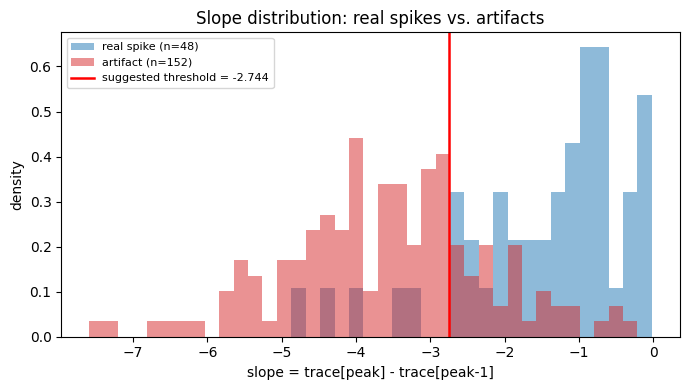

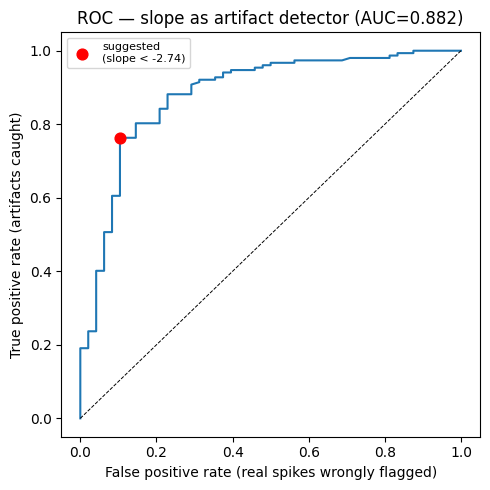

In [21]:
print(analysis_df.groupby("label")["slope"].describe())

slope_result = orient_and_find_threshold(analysis_df["label"], analysis_df["slope"], "slope")

plot_distribution(
    {0: analysis_df.loc[analysis_df.label == 0, "slope"], 1: analysis_df.loc[analysis_df.label == 1, "slope"]},
    xlabel="slope = trace[peak] - trace[peak-1]",
    title="Slope distribution: real spikes vs. artifacts",
    suggested_thr=slope_result["threshold"],
)
plot_roc(slope_result)


In [22]:
# Try your own cutoff and compare it against the suggested one above.
# Set to a number (e.g. -120.0) to use it everywhere downstream (section 11's
# right/wrong breakdown, section 13's saved filtered peaks) instead of the
# suggested threshold; leave as None to keep using the suggested one.
MANUAL_SLOPE_THRESHOLD = None

# This is the threshold that actually gets used from here on -- everything
# below (and section 11 / 13) reads SLOPE_THRESHOLD_ACTIVE, not slope_result
# directly, so setting MANUAL_SLOPE_THRESHOLD above changes downstream results.
SLOPE_THRESHOLD_ACTIVE = MANUAL_SLOPE_THRESHOLD if MANUAL_SLOPE_THRESHOLD is not None else slope_result["threshold"]
print(f"Active slope threshold: slope {slope_result['direction']} {SLOPE_THRESHOLD_ACTIVE:.3f}  "
      f"({'manual' if MANUAL_SLOPE_THRESHOLD is not None else 'suggested'})")

if MANUAL_SLOPE_THRESHOLD is not None:
    m_fpr, m_tpr = evaluate_threshold(analysis_df["slope"], analysis_df["label"],
                                       slope_result["sign"], MANUAL_SLOPE_THRESHOLD)
    print(f"  sensitivity (artifacts caught) = {m_tpr:.1%}")
    print(f"  specificity (real spikes kept) = {1 - m_fpr:.1%}")

    plot_distribution(
        {0: analysis_df.loc[analysis_df.label == 0, "slope"], 1: analysis_df.loc[analysis_df.label == 1, "slope"]},
        xlabel="slope = trace[peak] - trace[peak-1]",
        title="Slope distribution: suggested (red) vs. manual (green) threshold",
        suggested_thr=slope_result["threshold"], manual_thr=MANUAL_SLOPE_THRESHOLD,
    )
    plot_roc(slope_result, manual_point=(m_fpr, m_tpr, MANUAL_SLOPE_THRESHOLD))
else:
    print("MANUAL_SLOPE_THRESHOLD is None -- set it above to compare a manual cutoff against the suggested one.")


Active slope threshold: slope < -2.744  (suggested)
MANUAL_SLOPE_THRESHOLD is None -- set it above to compare a manual cutoff against the suggested one.


## 10. Method 2 results: half-amplitude width

       count      mean       std       min       25%       50%       75%  \
label                                                                      
0       48.0  0.166516  0.077838  0.047286  0.096439  0.167492  0.209629   
1      152.0  0.045873  0.022532  0.027530  0.032437  0.039009  0.048249   

            max  
label            
0      0.407297  
1      0.161376  
[halfwidth_samples] mean(real spike)=4.995   mean(artifact)=1.376
[halfwidth_samples] AUC=0.965   suggested cutoff: halfwidth_samples < 1.767  =>  flag as artifact
[halfwidth_samples] sensitivity (artifacts caught)=86.2%   specificity (real spikes kept)=93.8%
[halfwidth] equivalent cutoff in ms: 0.059 ms


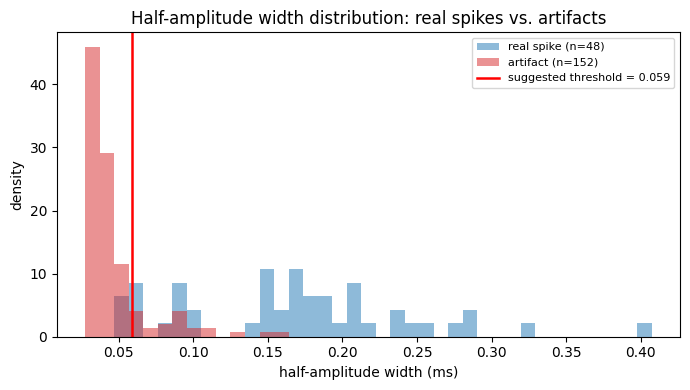

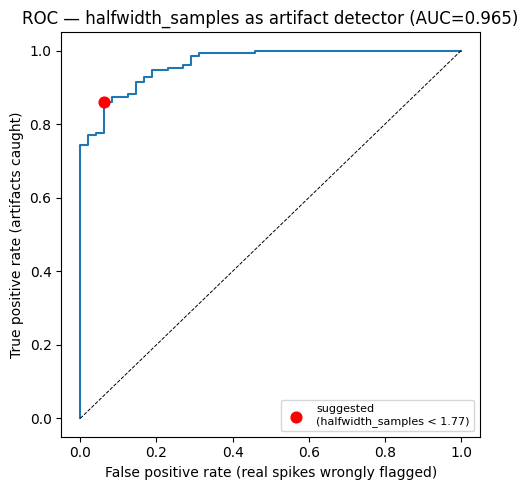

In [23]:
print(analysis_df.groupby("label")["halfwidth_ms"].describe())

# Threshold search is done in samples (native unit of the measurement);
hw_result = orient_and_find_threshold(analysis_df["label"], analysis_df["halfwidth_samples"], "halfwidth_samples")
hw_threshold_ms = hw_result["threshold"] / fs * 1000.0
print(f"[halfwidth] equivalent cutoff in ms: {hw_threshold_ms:.3f} ms")

plot_distribution(
    {0: analysis_df.loc[analysis_df.label == 0, "halfwidth_ms"], 1: analysis_df.loc[analysis_df.label == 1, "halfwidth_ms"]},
    xlabel="half-amplitude width (ms)",
    title="Half-amplitude width distribution: real spikes vs. artifacts",
    suggested_thr=hw_threshold_ms,
)
plot_roc(hw_result)


Active half-width threshold: halfwidth < 0.075 ms (2.25 samples)  (manual)
  sensitivity (artifacts caught) = 89.5%
  specificity (real spikes kept) = 85.4%


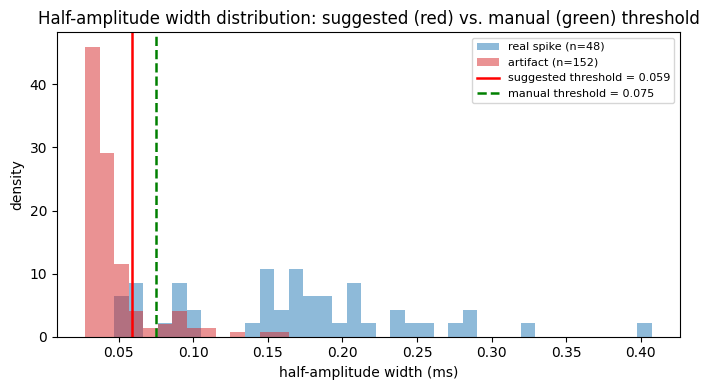

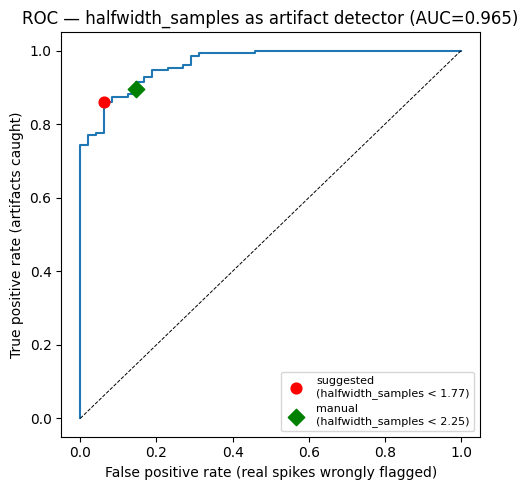

In [24]:
# Try your own cutoff (in ms) and compare it against the suggested one above.
# Set to a number (e.g. 0.25) to use it everywhere downstream (section 11's
# right/wrong breakdown, section 13's saved filtered peaks) instead of the
# suggested threshold; leave as None to keep using the suggested one.
MANUAL_HALFWIDTH_MS = 0.075

# This is the threshold that actually gets used from here on -- everything
# below (and section 11 / 13) reads HALFWIDTH_MS_ACTIVE / HALFWIDTH_SAMPLES_ACTIVE,
# not hw_result directly, so setting MANUAL_HALFWIDTH_MS above changes downstream results.
HALFWIDTH_MS_ACTIVE = MANUAL_HALFWIDTH_MS if MANUAL_HALFWIDTH_MS is not None else hw_threshold_ms
HALFWIDTH_SAMPLES_ACTIVE = HALFWIDTH_MS_ACTIVE * fs / 1000.0
print(f"Active half-width threshold: halfwidth {hw_result['direction']} {HALFWIDTH_MS_ACTIVE:.3f} ms "
      f"({HALFWIDTH_SAMPLES_ACTIVE:.2f} samples)  "
      f"({'manual' if MANUAL_HALFWIDTH_MS is not None else 'suggested'})")

if MANUAL_HALFWIDTH_MS is not None:
    manual_thr_samples = HALFWIDTH_SAMPLES_ACTIVE
    m_fpr, m_tpr = evaluate_threshold(analysis_df["halfwidth_samples"], analysis_df["label"],
                                       hw_result["sign"], manual_thr_samples)
    print(f"  sensitivity (artifacts caught) = {m_tpr:.1%}")
    print(f"  specificity (real spikes kept) = {1 - m_fpr:.1%}")

    plot_distribution(
        {0: analysis_df.loc[analysis_df.label == 0, "halfwidth_ms"], 1: analysis_df.loc[analysis_df.label == 1, "halfwidth_ms"]},
        xlabel="half-amplitude width (ms)",
        title="Half-amplitude width distribution: suggested (red) vs. manual (green) threshold",
        suggested_thr=hw_threshold_ms, manual_thr=MANUAL_HALFWIDTH_MS,
    )
    plot_roc(hw_result, manual_point=(m_fpr, m_tpr, manual_thr_samples))
else:
    print("MANUAL_HALFWIDTH_MS is None -- set it above to compare a manual cutoff against the suggested one.")


## 10b. 2D feature view: slope vs. half-amplitude width

Plots the two features together so you can inspect whether real spikes and artifacts separate better in joint feature space than in 1D.

- x-axis: slope (`slope_back`, 5-channel averaged)
- y-axis: half-amplitude width (ms, 5-channel averaged)
- colors: hand labels (blue = real spike, red = artifact)
- dashed lines: currently active 1D thresholds from sections 9 and 10

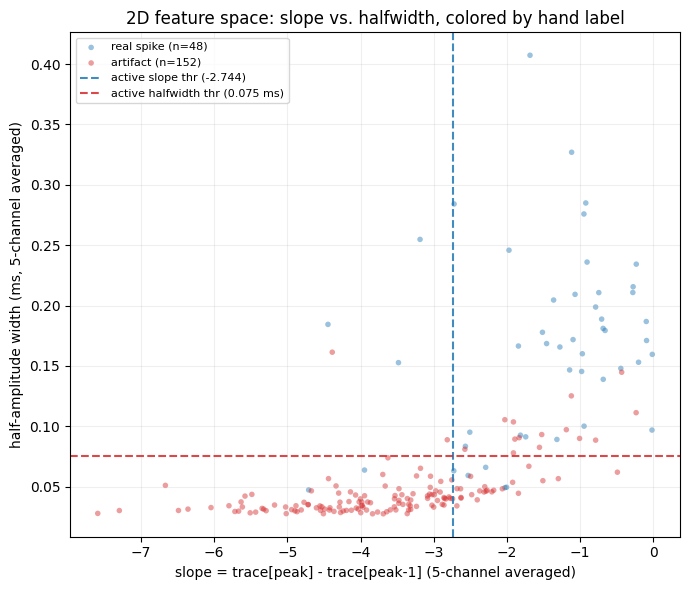

In [29]:
fig, ax = plt.subplots(figsize=(7, 6))

for lab, name, color in [(0, "real spike", "tab:blue"), (1, "artifact", "tab:red")]:
    m = analysis_df["label"].values == lab
    ax.scatter(
        analysis_df.loc[m, "slope"],
        analysis_df.loc[m, "halfwidth_ms"],
        s=16,
        alpha=0.45,
        color=color,
        edgecolors="none",
        label=f"{name} (n={m.sum():,})",
    )

if "SLOPE_THRESHOLD_ACTIVE" in globals() and np.isfinite(SLOPE_THRESHOLD_ACTIVE):
    ax.axvline(
        SLOPE_THRESHOLD_ACTIVE,
        color="tab:blue",
        ls="--",
        lw=1.5,
        alpha=0.85,
        label=f"active slope thr ({SLOPE_THRESHOLD_ACTIVE:.3f})",
    )

if "HALFWIDTH_MS_ACTIVE" in globals() and np.isfinite(HALFWIDTH_MS_ACTIVE):
    ax.axhline(
        HALFWIDTH_MS_ACTIVE,
        color="tab:red",
        ls="--",
        lw=1.5,
        alpha=0.85,
        label=f"active halfwidth thr ({HALFWIDTH_MS_ACTIVE:.3f} ms)",
    )

ax.set_xlabel("slope = trace[peak] - trace[peak-1] (5-channel averaged)")
ax.set_ylabel("half-amplitude width (ms, 5-channel averaged)")
ax.set_title("2D feature space: slope vs. halfwidth, colored by hand label")
ax.grid(alpha=0.2)
ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()

## 11. Where do the two methods get your hand labels wrong?

Restricted to the peaks you've hand-labeled (ground truth). Uses
`SLOPE_THRESHOLD_ACTIVE` / `HALFWIDTH_MS_ACTIVE` from sections 9/10 — i.e.
whichever threshold is currently active (your manual one if you set it,
otherwise the suggested one) — and checks it against your label, splitting
the labeled set into:

- both methods wrong
- slope wrong, half-width correct
- half-width wrong, slope correct
- (both correct — not plotted, nothing to inspect)

Each waveform (±3 channels, ±5 ms) is annotated so you can read the outcome
at a glance:

- **hand label**, shown just below the time axis at t=0: green ✓ = you
  labeled it a real spike, red ✗ = you labeled it an artifact.
- **method predictions**, shown just below the peak-channel trace at t=0:
  a filled circle = that method says "real", an x = that method says
  "artifact". Blue = slope method, red = half-width method.
- **orange caliper**: where the half-amplitude width was actually measured.


In [28]:
slope_result_active = {"sign": slope_result["sign"], "threshold": SLOPE_THRESHOLD_ACTIVE}
hw_result_active = {"sign": hw_result["sign"], "threshold": HALFWIDTH_SAMPLES_ACTIVE}

print(f"Using slope threshold: slope {slope_result['direction']} {SLOPE_THRESHOLD_ACTIVE:.3f} "
      f"({'manual' if MANUAL_SLOPE_THRESHOLD is not None else 'suggested'})")
print(f"Using halfwidth threshold: halfwidth {hw_result['direction']} {HALFWIDTH_MS_ACTIVE:.3f} ms "
      f"({'manual' if MANUAL_HALFWIDTH_MS is not None else 'suggested'})")

pred_slope_labeled = apply_threshold(analysis_df["slope"].values, slope_result_active)
pred_hw_labeled = apply_threshold(analysis_df["halfwidth_samples"].values, hw_result_active)
y_true = analysis_df["label"].values.astype(bool)  # True = hand-labeled artifact

slope_correct = pred_slope_labeled == y_true
hw_correct = pred_hw_labeled == y_true
n = len(analysis_df)

print(f"\nEvaluated against {n} hand-labeled peaks.")
print(f"slope method:      {(~slope_correct).sum()} wrong  ({(~slope_correct).mean():.1%})")
print(f"halfwidth method:  {(~hw_correct).sum()} wrong  ({(~hw_correct).mean():.1%})")

both_wrong = ~slope_correct & ~hw_correct
slope_only_wrong = ~slope_correct & hw_correct   # slope wrong, halfwidth correct
hw_only_wrong = slope_correct & ~hw_correct       # halfwidth wrong, slope correct
both_correct = slope_correct & hw_correct

print()
print(f"both methods wrong:            {both_wrong.sum()}  ({both_wrong.mean():.1%})")
print(f"slope wrong, halfwidth right:  {slope_only_wrong.sum()}  ({slope_only_wrong.mean():.1%})")
print(f"halfwidth wrong, slope right:  {hw_only_wrong.sum()}  ({hw_only_wrong.mean():.1%})")
print(f"both methods right:            {both_correct.sum()}  ({both_correct.mean():.1%})")


Using slope threshold: slope < -2.744 (suggested)
Using halfwidth threshold: halfwidth < 0.075 ms (manual)

Evaluated against 200 hand-labeled peaks.
slope method:      41 wrong  (20.5%)
halfwidth method:  23 wrong  (11.5%)

both methods wrong:            16  (8.0%)
slope wrong, halfwidth right:  25  (12.5%)
halfwidth wrong, slope right:  7  (3.5%)
both methods right:            152  (76.0%)


\n=== Both methods wrong (16 peaks) ===


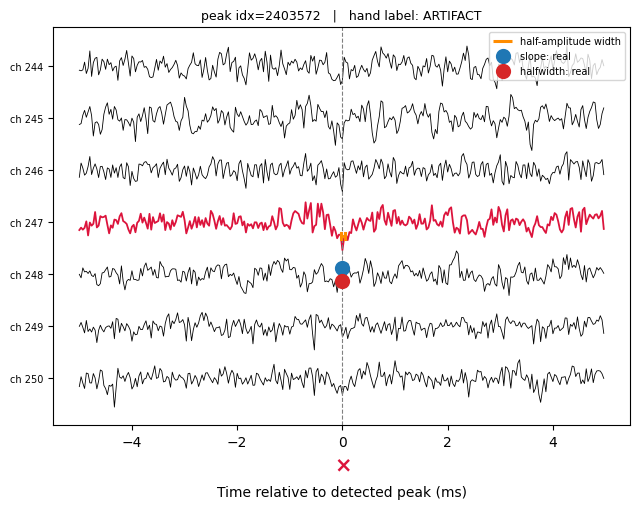

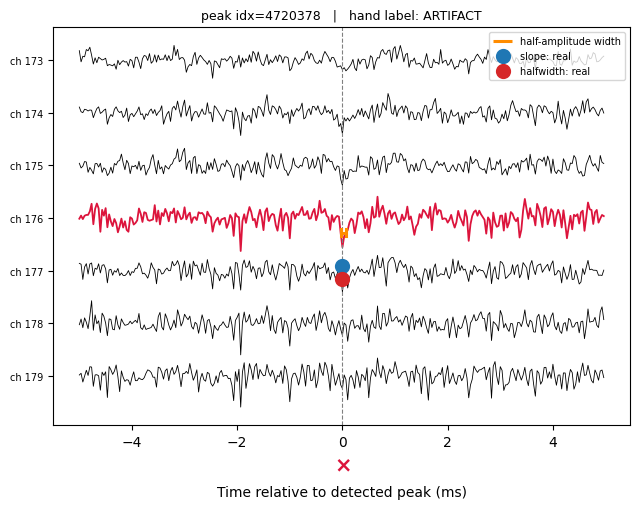

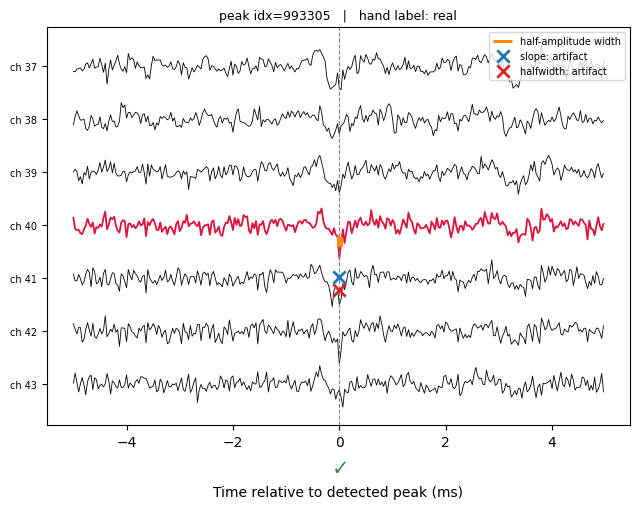

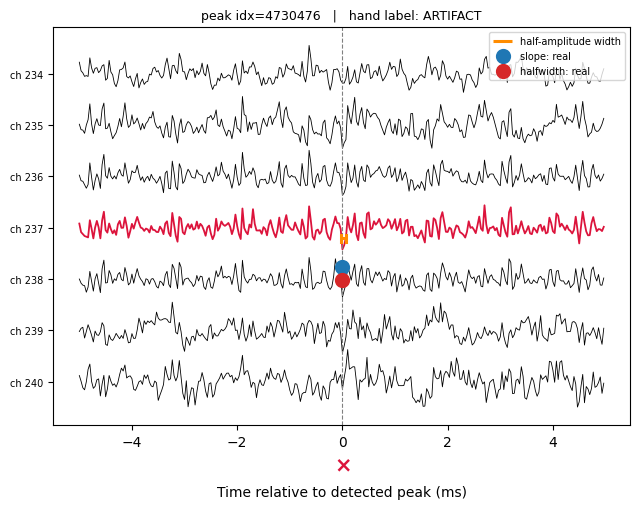

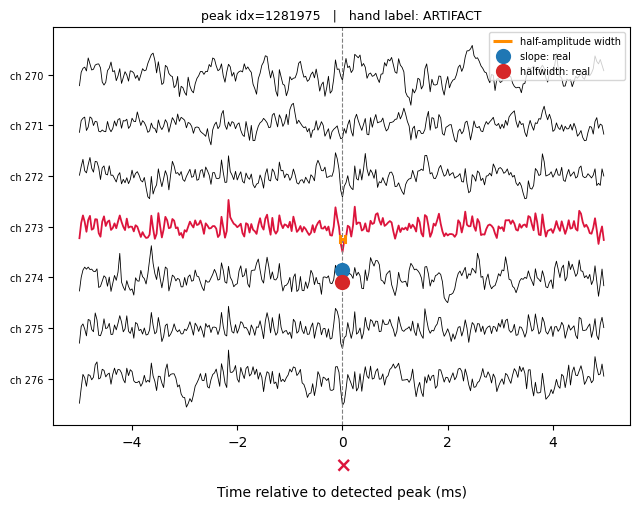

...

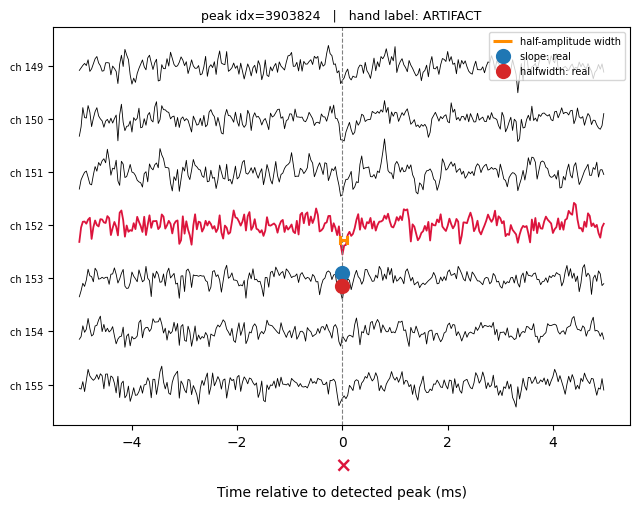

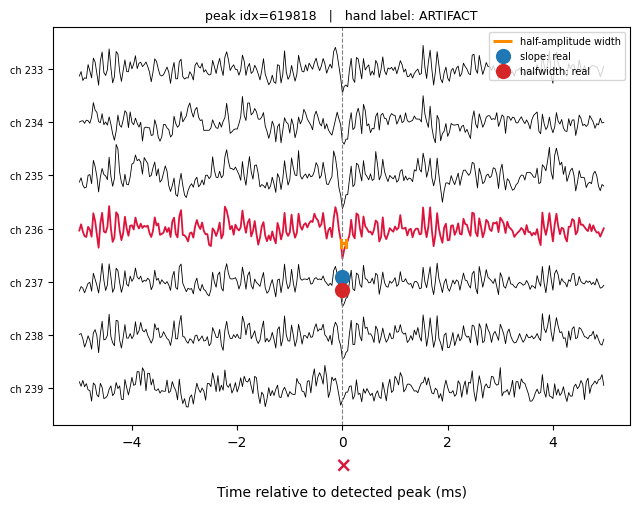

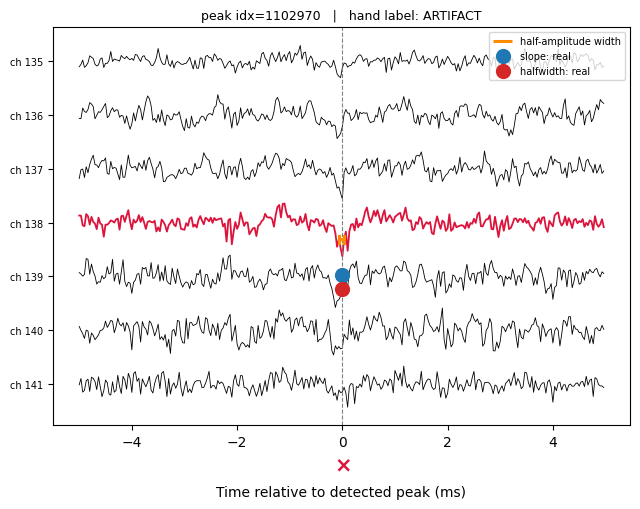

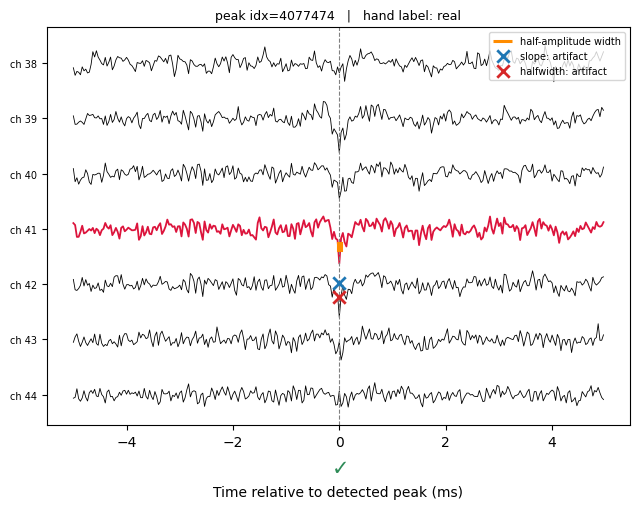

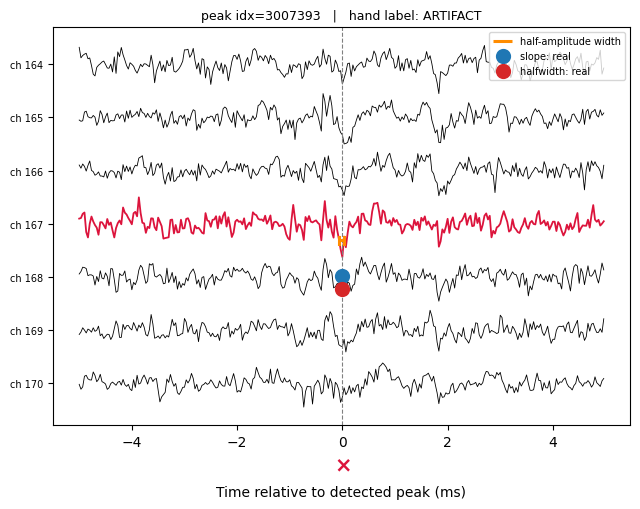

\n=== Slope wrong, halfwidth correct (25 peaks) ===


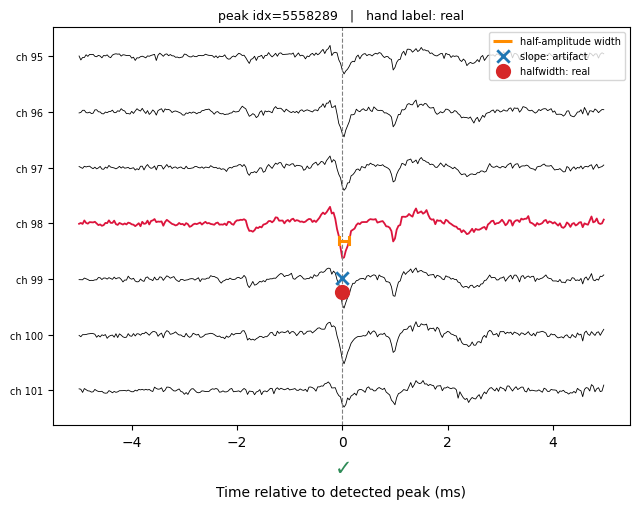

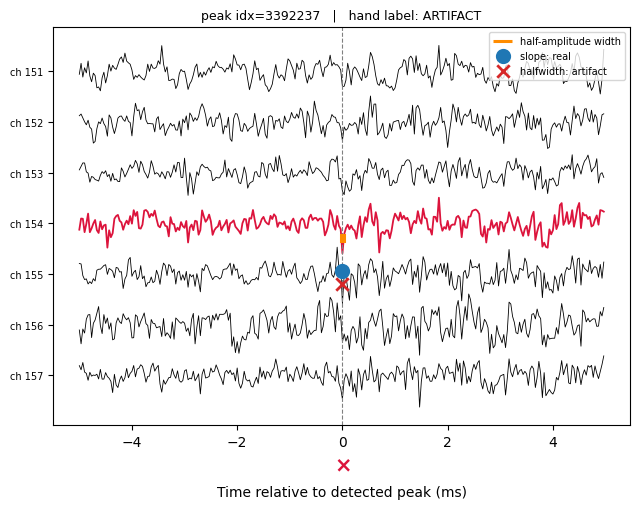

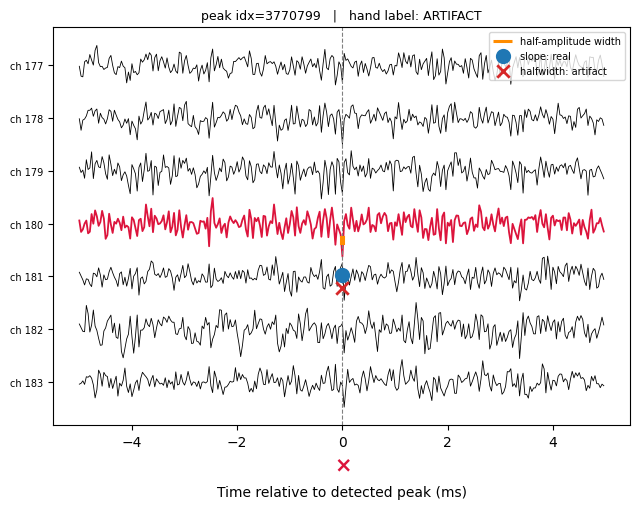

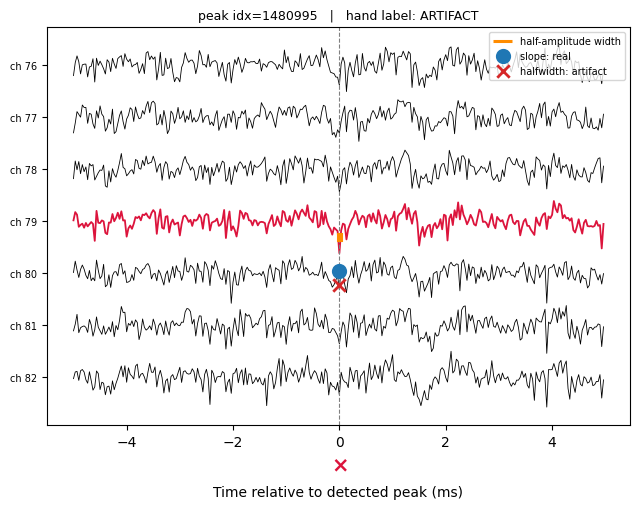

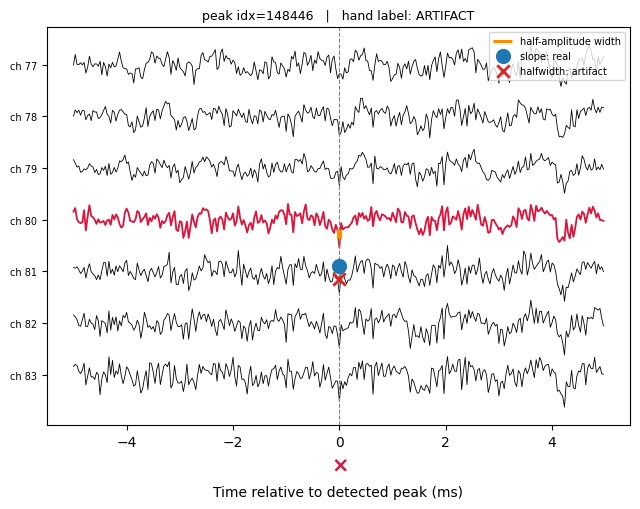

...

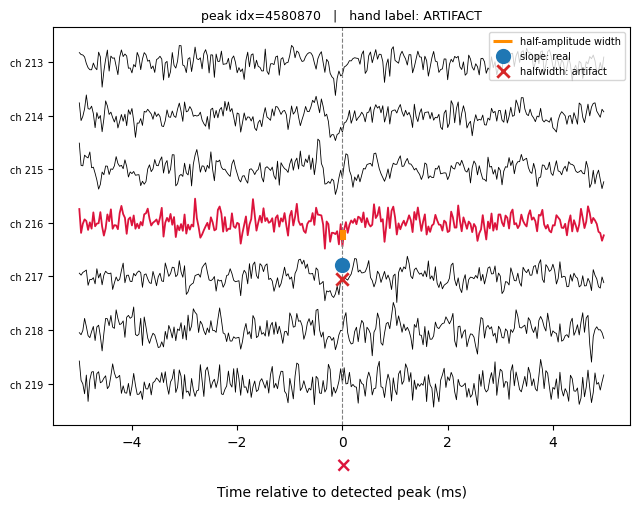

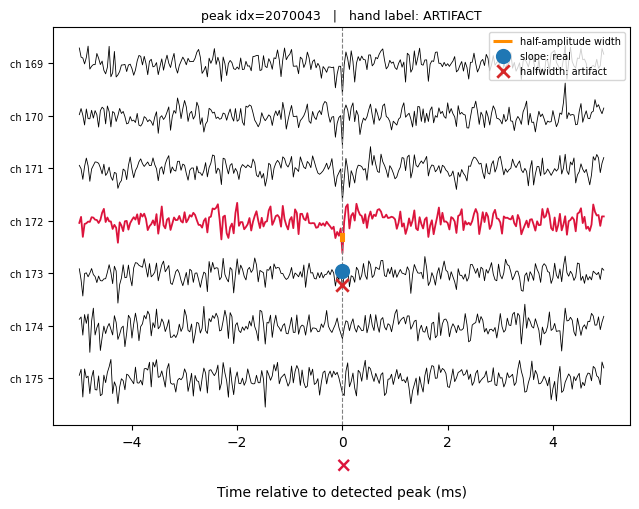

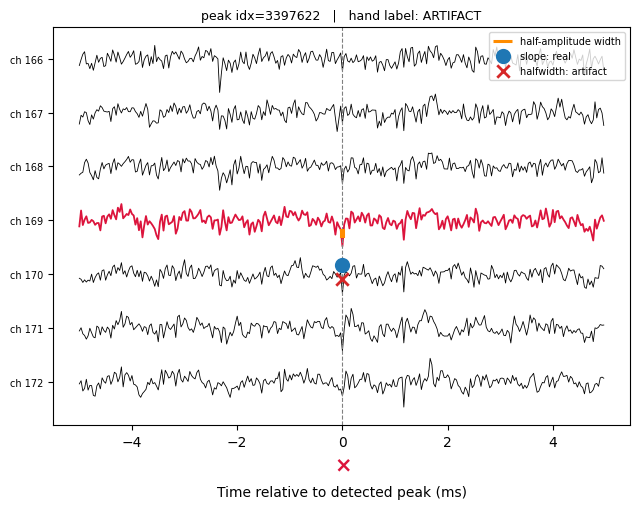

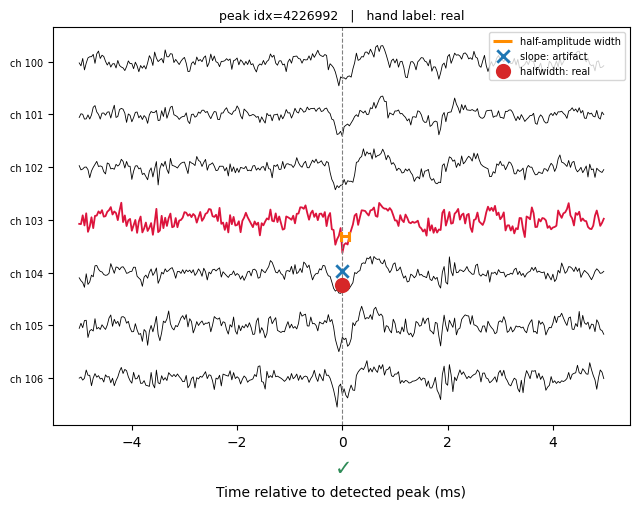

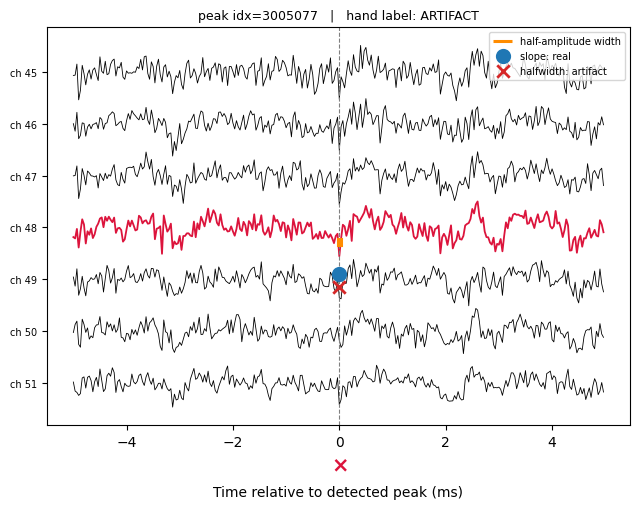

\n=== Halfwidth wrong, slope correct (7 peaks) ===


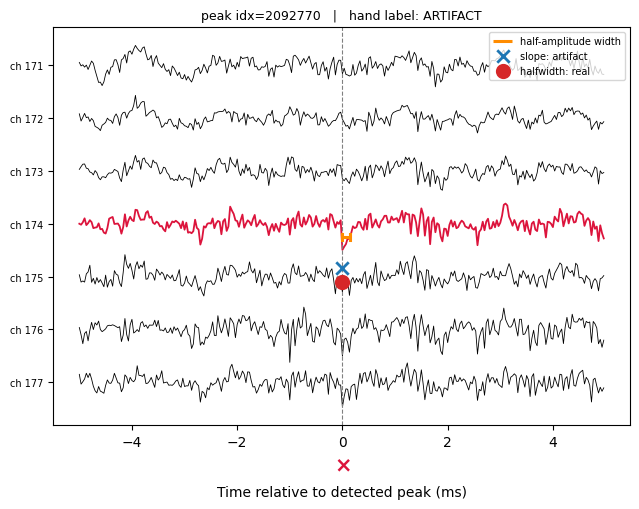

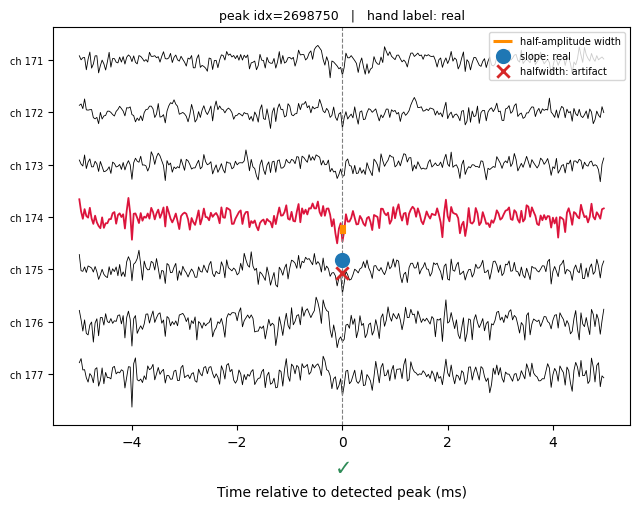

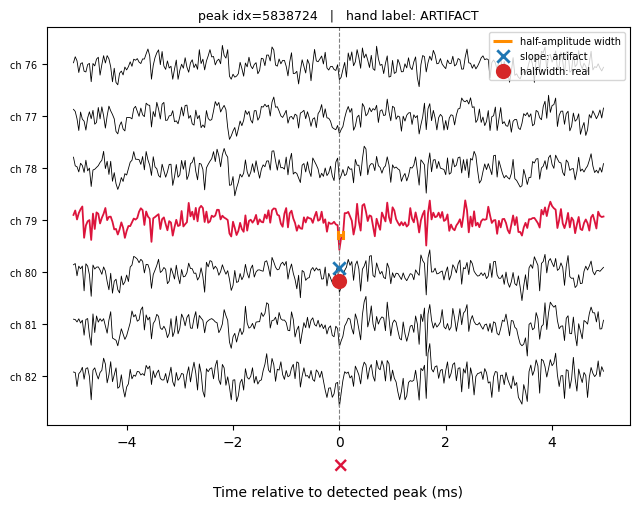

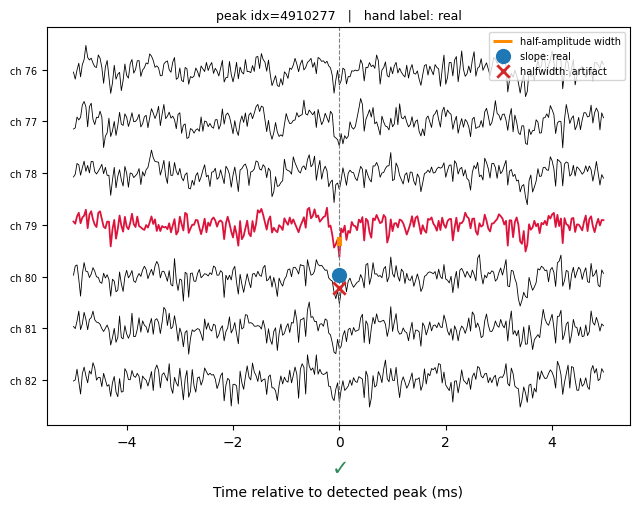

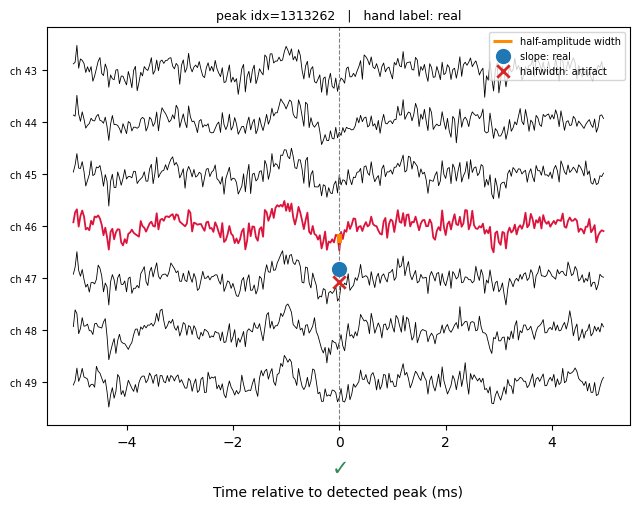

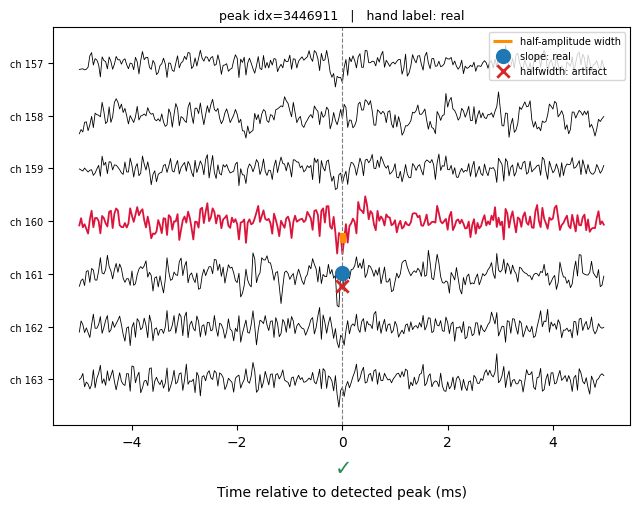

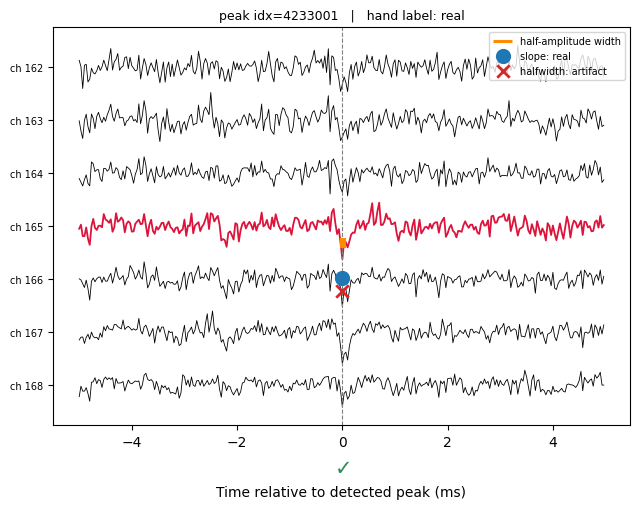

In [26]:
COMPARE_HALF_WIN_MS = 5.0
COMPARE_N_CONTEXT_CHANNELS = 3
_METHOD_OFFSET_FRAC = {"slope": 0.35, "halfwidth": 0.60}  # stacked below the peak-channel trace
_METHOD_COLOR = {"slope": "tab:blue", "halfwidth": "tab:red"}


def _find_halfamp_crossings(w, c):
    # Mirrors the per-peak walk in compute_halfwidths (section 6), but run on
    # an already-loaded trace snippet -- purely for drawing where the
    # half-amplitude width actually landed.
    peak_val = w[c]
    if peak_val == 0:
        return None
    sign = 1.0 if peak_val > 0 else -1.0
    half = peak_val / 2.0

    l = c
    while l - 1 >= 0 and (sign * w[l - 1] >= sign * half):
        l -= 1
    if l == 0:
        return None

    r = c
    while r + 1 < len(w) and (sign * w[r + 1] >= sign * half):
        r += 1
    if r == len(w) - 1:
        return None

    t_left = (half - w[l - 1]) / (w[l] - w[l - 1]) if w[l] != w[l - 1] else 0.5
    left_pos = (l - 1) + t_left
    t_right = (half - w[r]) / (w[r + 1] - w[r]) if w[r + 1] != w[r] else 0.5
    right_pos = r + t_right

    return left_pos, right_pos, half


def plot_labeled_comparison(i, true_artifact, pred_slope_artifact, pred_hw_artifact):
    p = peaks[i]
    s = int(p["sample_index"]) + SAMPLE_INDEX_OFFSET
    ch = int(p["channel_index"])
    half_win = max(int(round(COMPARE_HALF_WIN_MS * 1e-3 * fs)), 2)

    ch_lo = max(ch - COMPARE_N_CONTEXT_CHANNELS, 0)
    ch_hi = min(ch + COMPARE_N_CONTEXT_CHANNELS + 1, n_channels)
    lo = max(s - half_win, 0)
    hi = min(s + half_win, n_frames)

    chan_ids = all_channel_ids[ch_lo:ch_hi]
    traces = rec.get_traces(start_frame=lo, end_frame=hi, channel_ids=chan_ids)
    t_axis_ms = (np.arange(lo, hi) - s) / fs * 1000.0

    spacing = np.nanmax(np.abs(traces)) * 1.6 if traces.size else 1.0
    offsets = np.arange(traces.shape[1]) * -spacing
    ch_local = ch - ch_lo

    fig, ax = plt.subplots(figsize=(6.5, 0.4 * traces.shape[1] + 2.4))
    for c in range(traces.shape[1]):
        is_peak_chan = (ch_lo + c) == ch
        ax.plot(t_axis_ms, traces[:, c] + offsets[c],
                color="crimson" if is_peak_chan else "black",
                lw=1.3 if is_peak_chan else 0.6)
    ax.axvline(0, color="0.5", lw=0.8, ls="--")

    # peak-channel trace value at t=0, to anchor the method-prediction markers
    peak_local_sample = int(round(s - lo))
    peak_local_sample = min(max(peak_local_sample, 0), traces.shape[0] - 1)
    peak_trace_val = traces[peak_local_sample, ch_local]
    base_y = offsets[ch_local] + peak_trace_val

    # half-amplitude width: horizontal bar between the two crossing points,
    # drawn at the height of the half-amplitude level on the peak channel
    w_peak = traces[:, ch_local].astype(np.float64)
    crossing = _find_halfamp_crossings(w_peak, peak_local_sample)
    if crossing is not None:
        left_pos, right_pos, half_amp = crossing
        t_left_ms = (lo + left_pos - s) / fs * 1000.0
        t_right_ms = (lo + right_pos - s) / fs * 1000.0
        y_half = offsets[ch_local] + half_amp
        tick = 0.06 * spacing
        ax.plot([t_left_ms, t_right_ms], [y_half, y_half], color="darkorange", lw=2.2,
                solid_capstyle="butt", zorder=6, label="half-amplitude width")
        ax.plot([t_left_ms, t_left_ms], [y_half - tick, y_half + tick], color="darkorange", lw=2.2, zorder=6)
        ax.plot([t_right_ms, t_right_ms], [y_half - tick, y_half + tick], color="darkorange", lw=2.2, zorder=6)

    for name, pred_artifact in [("slope", pred_slope_artifact), ("halfwidth", pred_hw_artifact)]:
        y = base_y - _METHOD_OFFSET_FRAC[name] * spacing
        marker = "x" if pred_artifact else "o"
        ax.scatter([0], [y], color=_METHOD_COLOR[name], marker=marker, s=80, zorder=5, lw=2,
                   label=f"{name}: {'artifact' if pred_artifact else 'real'}")

    # hand label: check/cross just below the time axis at t=0
    ax.annotate("$\\mathbf{\\times}$" if true_artifact else "$\\mathbf{\\checkmark}$",
                xy=(0, 0), xycoords=("data", "axes fraction"),
                xytext=(0, -22), textcoords="offset points",
                ha="center", va="top", fontsize=15,
                color="crimson" if true_artifact else "seagreen")

    ax.set_yticks(offsets)
    ax.set_yticklabels([f"ch {ch_lo + c}" for c in range(traces.shape[1])], fontsize=7)
    ax.set_xlabel("Time relative to detected peak (ms)", labelpad=26)
    ax.set_title(f"peak idx={i}   |   hand label: {'ARTIFACT' if true_artifact else 'real'}", fontsize=9)
    ax.legend(fontsize=7, loc="upper right")
    plt.tight_layout()
    return fig


def show_group(mask, title):
    print(f"\\n=== {title} ({int(mask.sum())} peaks) ===")
    if mask.sum() == 0:
        print("  none")
        return
    sub_idx = analysis_df.loc[mask, "idx"].values
    sub_label = y_true[mask]
    sub_ps = pred_slope_labeled[mask]
    sub_ph = pred_hw_labeled[mask]
    for i, lbl, ps_i, ph_i in zip(sub_idx, sub_label, sub_ps, sub_ph):
        plot_labeled_comparison(int(i), bool(lbl), bool(ps_i), bool(ph_i))
        plt.show()


show_group(both_wrong, "Both methods wrong")
show_group(slope_only_wrong, "Slope wrong, halfwidth correct")
show_group(hw_only_wrong, "Halfwidth wrong, slope correct")


## 12. Appendix: slope vs. amplitude

Checks whether artifacts separate on slope alone or only in combination with amplitude (using the trace value at the peak sample, computed in section 6 — useful if a slope-only cutoff ends up too aggressive).

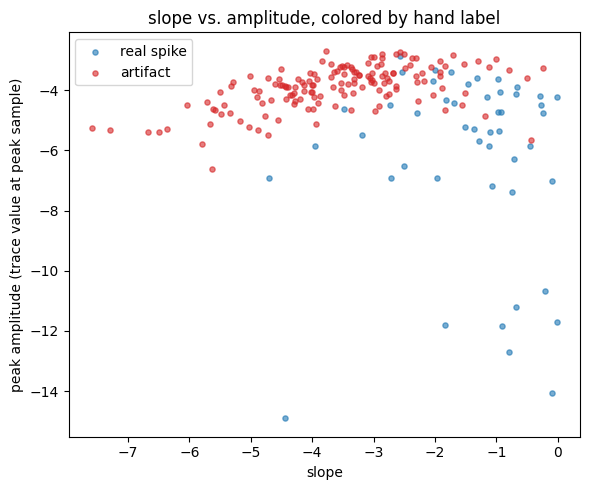

In [33]:
fig, ax = plt.subplots(figsize=(6, 5))
for lab, name, color in [(0, "real spike", "tab:blue"), (1, "artifact", "tab:red")]:
    m = analysis_df["label"].values == lab
    idx_m = analysis_df.loc[m, "idx"].values
    ax.scatter(analysis_df.loc[m, "slope"], peak_amp[idx_m], s=14, alpha=0.6, label=name, color=color)
ax.set_xlabel("slope")
ax.set_ylabel("peak amplitude (trace value at peak sample)")
ax.legend()
ax.set_title("slope vs. amplitude, colored by hand label")
plt.tight_layout()
plt.show()


## 13. Save filtered peaks for each method

Applies each method's **active** threshold (`SLOPE_THRESHOLD_ACTIVE` /
`HALFWIDTH_MS_ACTIVE` from sections 9/10 — your manual override if you set
one, otherwise the suggested threshold; same ones used in section 11) to
**every** peak, not just the labeled ones, and saves the surviving peaks as
new `.npy` files next to the original, named with the threshold that
produced them.

Peaks whose feature is `NaN` (edge-of-recording, or no half-amplitude
crossing found within the search window) are kept rather than silently
dropped, since they can't be evaluated against a threshold.


In [ ]:
slope_threshold_used = SLOPE_THRESHOLD_ACTIVE
hw_threshold_used_ms = HALFWIDTH_MS_ACTIVE
hw_threshold_used_samples = HALFWIDTH_SAMPLES_ACTIVE

pred_slope_artifact_all = apply_threshold(
    slope_back, {"sign": slope_result["sign"], "threshold": slope_threshold_used})
pred_hw_artifact_all = apply_threshold(
    halfwidth_samples, {"sign": hw_result["sign"], "threshold": hw_threshold_used_samples})

slope_nan = np.isnan(slope_back)
hw_nan = np.isnan(halfwidth_samples)
print(f"{slope_nan.sum():,} peaks have NaN slope (kept, not filtered)")
print(f"{hw_nan.sum():,} peaks have NaN half-width (kept, not filtered)")

keep_slope = (~pred_slope_artifact_all) | slope_nan
keep_hw = (~pred_hw_artifact_all) | hw_nan

peaks_slope_filtered = peaks[keep_slope]
peaks_hw_filtered = peaks[keep_hw]

print(f"slope filter:     kept {keep_slope.sum():,} / {len(peaks):,} peaks "
      f"(dropped {(~keep_slope).sum():,}, threshold: slope {slope_result['direction']} {slope_threshold_used:.3f})")
print(f"halfwidth filter: kept {keep_hw.sum():,} / {len(peaks):,} peaks "
      f"(dropped {(~keep_hw).sum():,}, threshold: halfwidth {hw_result['direction']} {hw_threshold_used_ms:.3f} ms)")

slope_out_path = PEAKS_PATH.parent / f"{PEAKS_PATH.stem}_slopesfiltered_5averaged_{slope_threshold_used:.3f}.npy"
hw_out_path = PEAKS_PATH.parent / f"{PEAKS_PATH.stem}_halfwidthsfiltered_5averaged_{hw_threshold_used_ms:.3f}ms.npy"

np.save(slope_out_path, peaks_slope_filtered)
np.save(hw_out_path, peaks_hw_filtered)

print(f"\nSaved: {slope_out_path}")
print(f"Saved: {hw_out_path}")

0 peaks have NaN slope (kept, not filtered)
0 peaks have NaN half-width (kept, not filtered)
slope filter:     kept 2,610,601 / 5,855,870 peaks (dropped 3,245,269, threshold: slope < -2.744)
halfwidth filter: kept 1,932,711 / 5,855,870 peaks (dropped 3,923,159, threshold: halfwidth < 0.075 ms)

Saved: /nexus/posix0/MBR-neuralsystems/ephys/GLC7248/GLC7248_a_g1/preprocessed/thresholding_peaks_3.5_ts5600_teend/_sliced_recording/thresholding_peaks_3.5_ts5600_teend/peaks_combined2_sorted_slopesfiltered_-2.744.npy
Saved: /nexus/posix0/MBR-neuralsystems/ephys/GLC7248/GLC7248_a_g1/preprocessed/thresholding_peaks_3.5_ts5600_teend/_sliced_recording/thresholding_peaks_3.5_ts5600_teend/peaks_combined2_sorted_halfwidthsfiltered_0.075ms.npy


#### WAVEFORM PLOT




all peaks: 5,855,870 peaks configured
slope filtered: 2,610,601 peaks configured
halfwidth filtered: 1,932,711 peaks configured


In [ ]:
# =====================================================================
# STANDALONE waveform viewer with peak overlays -- self-contained, no
# dependency on any other cell in this notebook.
# =====================================================================

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from mua_pipeline import load_data as load_data_mua

# --- Recording ---
VIEWER_RECORDING_PATH = Path(r"/nexus/posix0/MBR-neuralsystems/ephys/GLC7248/GLC7248_a_g1/preprocessed")
VIEWER_SAMPLE_INDEX_OFFSET = 0  # sample_index convention relative to VIEWER_RECORDING_PATH above

# --- What part of the recording to show ---
WAVEFORM_VIEW = {
    "time_window_s": (5700.0, 5700.05),   # explicit recording-time window in seconds
    "channel_window": (0, 384),         # explicit [start, end) channel window
    "center_on_peak_idx": None,           # e.g. 12345 to center the view on one peak instead
    "center_peaks_path": None,            # .npy file center_on_peak_idx indexes into (required if center_on_peak_idx is set)
}

# --- Which peak sets to overlay, and how to draw them. Add/remove/edit
# entries freely. "path" = None skips that overlay entirely. ---
WAVEFORM_PEAK_OVERLAYS = [
    {
        "label": "all peaks",
        "path": r"/nexus/posix0/MBR-neuralsystems/ephys/GLC7248/GLC7248_a_g1/preprocessed/thresholding_peaks_3.5_ts5600_teend/_sliced_recording/thresholding_peaks_3.5_ts5600_teend/peaks_combined2_sorted.npy",
        "color": "#e6194b",
        "marker": "o",
        "size": 8,
        "alpha": 0.9,
        "y_offset_fraction": -0.10,
    },
    {
        "label": "slope filtered",
        "path": r"/nexus/posix0/MBR-neuralsystems/ephys/GLC7248/GLC7248_a_g1/preprocessed/thresholding_peaks_3.5_ts5600_teend/_sliced_recording/thresholding_peaks_3.5_ts5600_teend/peaks_combined2_sorted_slopesfiltered_5averaged_-2.744.npy",
        "color": "#3cb44b",
        "marker": "o",
        "size": 8,
        "alpha": 0.9,
        "y_offset_fraction": -0.22,
    },
    {
        "label": "halfwidth filtered",
        "path": r"/nexus/posix0/MBR-neuralsystems/ephys/GLC7248/GLC7248_a_g1/preprocessed/thresholding_peaks_3.5_ts5600_teend/_sliced_recording/thresholding_peaks_3.5_ts5600_teend/peaks_combined2_sorted_halfwidthsfiltered_5averaged_0.075ms.npy",
        "color": "#4363d8",
        "marker": "o",
        "size": 8,
        "alpha": 0.9,
        "y_offset_fraction": -0.34,
    },
]

# --- Load recording ---
_viewer_rec = load_data_mua(str(VIEWER_RECORDING_PATH), n_jobs=1)
_viewer_fs = _viewer_rec.sampling_frequency
_viewer_n_channels = _viewer_rec.get_num_channels()
_viewer_n_frames = _viewer_rec.get_num_frames()
_viewer_all_channel_ids = _viewer_rec.get_channel_ids()

# --- Load each overlay's peaks from its own path ---
for _overlay in WAVEFORM_PEAK_OVERLAYS:
    _path = _overlay.get("path")
    _overlay["peaks"] = np.load(_path) if _path is not None else None


def _resolve_waveform_view(view_cfg):
    center_idx = view_cfg.get("center_on_peak_idx")
    if center_idx is not None:
        center_peaks_path = view_cfg.get("center_peaks_path")
        if center_peaks_path is None:
            raise ValueError("Set center_peaks_path when using center_on_peak_idx.")
        center_peaks = np.load(center_peaks_path)
        p = center_peaks[int(center_idx)]
        center_sample = int(p["sample_index"]) + VIEWER_SAMPLE_INDEX_OFFSET
        center_channel = int(p["channel_index"])
        half_window_frames = max(int(round(view_cfg.get("half_window_ms", 8.0) * 1e-3 * _viewer_fs)), 2)
        channels_each_side = int(view_cfg.get("n_channels_each_side", 10))

        start_frame = max(center_sample - half_window_frames, 0)
        end_frame = min(center_sample + half_window_frames, _viewer_n_frames)
        ch0 = max(center_channel - channels_each_side, 0)
        ch1 = min(center_channel + channels_each_side + 1, _viewer_n_channels)
        return start_frame / _viewer_fs, end_frame / _viewer_fs, ch0, ch1, center_sample / _viewer_fs

    time_window_s = view_cfg.get("time_window_s")
    channel_window = view_cfg.get("channel_window")
    if time_window_s is None or channel_window is None:
        raise ValueError("Set either center_on_peak_idx, or both time_window_s and channel_window.")

    t0, t1 = map(float, time_window_s)
    ch0, ch1 = map(int, channel_window)
    if not (t1 > t0):
        raise ValueError("time_window_s must satisfy end > start")
    if not (ch1 > ch0):
        raise ValueError("channel_window must satisfy end > start")

    t0 = max(t0, 0.0)
    t1 = min(t1, _viewer_n_frames / _viewer_fs)
    ch0 = max(ch0, 0)
    ch1 = min(ch1, _viewer_n_channels)
    return t0, t1, ch0, ch1, None


def plot_waveform_peak_overlays(view_cfg, overlays):
    t0, t1, ch0, ch1, center_time_s = _resolve_waveform_view(view_cfg)
    start_frame = max(int(np.floor(t0 * _viewer_fs)), 0)
    end_frame = min(int(np.ceil(t1 * _viewer_fs)), _viewer_n_frames)
    if end_frame <= start_frame:
        raise ValueError("Resolved time window is empty")
    if ch1 <= ch0:
        raise ValueError("Resolved channel window is empty")

    chan_ids = _viewer_all_channel_ids[ch0:ch1]
    traces = _viewer_rec.get_traces(start_frame=start_frame, end_frame=end_frame, channel_ids=chan_ids)
    t_axis_s = np.arange(start_frame, end_frame) / _viewer_fs
    spacing = np.nanmax(np.abs(traces)) * 1.6 if traces.size else 1.0
    if not np.isfinite(spacing) or spacing == 0:
        spacing = 1.0
    offsets = np.arange(traces.shape[1]) * -spacing

    fig, ax = plt.subplots(figsize=(10, max(4, 0.33 * traces.shape[1] + 1.5)))
    for c in range(traces.shape[1]):
        ax.plot(t_axis_s, traces[:, c] + offsets[c], color="black", lw=0.5)

    for overlay in overlays:
        pk = overlay.get("peaks")
        if pk is None or len(pk) == 0:
            continue

        pk_samples = pk["sample_index"].astype(np.int64) + VIEWER_SAMPLE_INDEX_OFFSET
        mask = (
            (pk_samples >= start_frame)
            & (pk_samples < end_frame)
            & (pk["channel_index"] >= ch0)
            & (pk["channel_index"] < ch1)
        )

        if not np.any(mask):
            continue

        pk_samples_win = pk_samples[mask]
        pk_channels_win = pk["channel_index"][mask].astype(int) - ch0
        pk_times_win_s = pk_samples_win / _viewer_fs
        first = True
        for sample_idx, channel_idx, peak_time_s in zip(pk_samples_win, pk_channels_win, pk_times_win_s):
            trace_idx = int(sample_idx - start_frame)
            trace_val = traces[trace_idx, channel_idx]
            dot_y = offsets[channel_idx] + trace_val + overlay.get("y_offset_fraction", -0.1) * spacing

            ax.scatter(
                peak_time_s,
                dot_y,
                color=overlay.get("color", "#e6194b"),
                marker=overlay.get("marker", "o"),
                s=overlay.get("size", 18),
                alpha=overlay.get("alpha", 0.9),
                zorder=4,
                label=overlay.get("label", "peaks") if first else "",
            )
            first = False

    if center_time_s is not None:
        ax.axvline(center_time_s, color="0.5", lw=0.8, ls="--")

    ax.set_yticks(offsets)
    ax.set_yticklabels([f"ch {ch}" for ch in range(ch0, ch1)], fontsize=7)
    ax.set_xlim(t_axis_s[0], t_axis_s[-1])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Channel")
    ax.set_title(
        f"Waveform snippet with peak overlays | t=[{t0:.6f}, {t1:.6f}] s | ch=[{ch0}, {ch1})",
        fontsize=10,
    )
    ax.grid(axis="x", alpha=0.12)

    handles, labels = ax.get_legend_handles_labels()
    dedup = {}
    for handle, label in zip(handles, labels):
        if label and label not in dedup:
            dedup[label] = handle
    if dedup:
        ax.legend(dedup.values(), dedup.keys(), loc="upper right", fontsize=8, framealpha=0.8)

    plt.tight_layout()
    return fig, ax


fig, ax = plot_waveform_peak_overlays(WAVEFORM_VIEW, WAVEFORM_PEAK_OVERLAYS)
plt.show()

for overlay in WAVEFORM_PEAK_OVERLAYS:
    pk = overlay.get("peaks")
    n_pk = 0 if pk is None else len(pk)
    print(f"{overlay.get('label', 'peaks')}: {n_pk:,} peaks configured")